# Speed Prediction — 파생/추가 피처 빠른 테스트 (LightGBM)

**목적**: `11_speed_model_baseline.ipynb`의 LightGBM 결과를 기준점으로 두고, 파생 피처와 신규 외부 피처를 추가했을 때 실제로 개선되는지 **LightGBM 하나로만** 빠르게 확인합니다.

**핵심 전제**: 여기서 만드는 피처들은 전부 **미관측 링크(29.25%)에도 쓸 수 있는 범용 피처** 후보를 찾는 작업입니다 — 관측 링크는 자기 자신의 과거 속도 이력(Model A 방식)을 쓰면 되므로 이 노트북의 범위가 아닙니다.

**버전 변경 이력**
- 1차: 버스전용차로를 30% 겹침 기준 boolean으로 추가 (gain 0.17%)
- 2차: 버스전용차로를 겹침 비율(연속값)로 바꾸고, **추정교통량**(2024년 평일 기준 AADT+시간대별)을 `ITS LINK ID` 매칭으로 추가
- 3차: **인접 실측 이웃 속도** 추가 — 1홉 이웃 중 관측된 링크들의 그 시각 실제 속도 평균
- 4차: **어린이보호구역 근접·보행자사고다발지역·과속방지턱** 추가
- **5차(데이터셋 전환)**: 파이프라인 리팩토링으로 이 노트북이 읽던 `seoul_link_speed_dem_weather_merged.csv`가 삭제됐습니다. `seoul_link_dimension.csv` + `seoul_link_speed_fact.csv`로 옮기면서, 1~4차에서 직접 공간조인으로 만들던 `bus_lane_ratio`/`school_zone_count`/`accident_hotspot_count`/`speed_bump_count`/`traffic_volume_aadt`/`traffic_volume_hourly`가 이제 **`src/pipeline/04`·`05`가 미리 계산해 테이블에 포함**되어 있어, 이 노트북에서 다시 공간조인할 필요가 없어졌습니다(구 1~3절 삭제). 5차는 순수 이관이라 4차와 같은 피처 집합 — 수치가 비슷하게 재현되는지가 마이그레이션 검증입니다.
- **6차(생활인구)**: `notebooks/14_accident_hotspot_classification.ipynb`(다른 브랜치, 사고다발지역 분류 실험)에서 쓰던 **생활인구**(서울시 250m 격자 + 행정동, 2026년 7월 일별) 피처를 속도 예측에도 추가합니다. 아직 `pipeline/04`/`05`에는 안 붙어 있는 실험 단계 데이터라 이 노트북에서 직접 로드·매칭합니다.
- **7차(이번, 형제 노트북/스크립트에서 검증된 아이디어 이식)**: 두 가지를 추가합니다.
  1. **도로망 위상·파생 28개** — `pipeline/04`가 이미 계산해 `seoul_link_dimension.csv`에 넣어뒀는데 이 노트북은 지금까지 안 쓰고 있었습니다. `notebooks/13_tier_split_evaluation.ipynb`가 같은 피처만 따로 떼서 검증한 결과, 이웃이 없는 미관측 링크(C 계층)에서 R²를 +0.043 올려 외부컨텍스트(+0.010)보다 4배 더 기여했습니다.
  2. **강수·첨두시 파생 피처** — `log_precip`, `rain_class`(강수 등급 범주형), `rain_morning_peak`/`rain_evening_peak`(비×첨두 교차항), `rain_x_max_spd`, `is_morning_peak`/`is_evening_peak` — 정식 `src/11_evaluate_speed_model.py`가 쓰는데 이 노트북엔 없던 파생 피처입니다. 다만 그 스크립트는 첨두시를 `시간코드`값을 그대로(보정 없이) 써서 실제로는 한 시간 이른 구간을 "첨두"로 표시하고 있었습니다 — 우리는 4절에서 이미 확립한 `시간코드 - 1 = 실제 시각` 규칙대로 정확히 보정해서 만듭니다.

**비교 기준점(재실행 없이 인용)**

| model | rmse | mae | r2 |
| --- | --- | --- | --- |
| LightGBM (11번, 원본 피처) | 7.653 | 5.765 | 0.610 |
| LightGBM (1차: +파생/버스전용차로 boolean) | 7.629 | 5.747 | 0.613 |
| LightGBM (2차: +비율/교통량) | 7.508 | 5.659 | 0.625 |
| LightGBM (3차: +인접 실측 이웃 속도) | 6.197 | 4.462 | 0.744 |
| LightGBM (4차: +스쿨존/사고다발지역/과속방지턱, 구 스키마) | 6.180 | 4.449 | 0.746 |

**캐싱**: 원본 결합 결과를 `data/interim/notebook_cache/nb12_feature_cache_v6.parquet`에 캐싱합니다(위상 피처가 추가되어 스키마가 또 바뀌었으므로 v5와 분리). 인접 이웃 속도·생활인구는 캐시 이후 단계에서 매번 새로 계산합니다.

In [1]:
import gc
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DOCS_FIGURES_DIR = PROJECT_ROOT / "docs" / "figures" / "model"
DOCS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 새 스키마: 정적(링크당 1행) + 동적(링크x날짜x시간) 분리, LINK_ID로 merge
DIMENSION_PATH = PROCESSED_DIR / "seoul_link_dimension.csv"
FACT_PATH = PROCESSED_DIR / "seoul_link_speed_fact.csv"
SEOUL_LINK_SHP = INTERIM_DIR / "seoul_link.shp"

# 생활인구(실험용, 아직 파이프라인에 안 붙음) — notebooks/14_accident_hotspot_classification.ipynb와 동일 원본
GRID_MATCH_SHP = RAW_DIR / "traffic" / "match" / "match.shp"                 # 250m격자 CELL_ID -> geometry
GRID_POP_DIR = RAW_DIR / "traffic" / "250_LOCAL_RESD_202607"                 # 250m 격자 생활인구(일별)
DONG_POP_DIR = RAW_DIR / "traffic" / "250_LOCAL_RESD_ADMDONG_202607"         # 행정동 생활인구(일별)

CACHE_PATH = INTERIM_DIR / "notebook_cache" / "nb12_feature_cache_v6.parquet"
CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
COLOR_RMSE = "#2a78d6"   # dataviz 팔레트 slot 1 blue
COLOR_MAE = "#eb6834"    # dataviz 팔레트 slot 2 orange
COLOR_SEQ = "#3987e5"

BASELINE_11 = {"model": "LightGBM (11번, 원본 피처)", "rmse": 7.652966670997528, "mae": 5.764899686592482, "r2": 0.6101212805788272}
BASELINE_V1 = {"model": "LightGBM (1차: +파생/버스전용차로 boolean)", "rmse": 7.629313, "mae": 5.747021, "r2": 0.612528}
BASELINE_V2 = {"model": "LightGBM (2차: +비율/교통량)", "rmse": 7.508456, "mae": 5.658695, "r2": 0.624706}
BASELINE_V3 = {"model": "LightGBM (3차: +인접 실측 이웃 속도)", "rmse": 6.197259, "mae": 4.461506, "r2": 0.744336}
BASELINE_V4 = {"model": "LightGBM (4차: +스쿨존/사고다발지역/과속방지턱, 구 스키마)", "rmse": 6.179658, "mae": 4.448957, "r2": 0.745786}

## 1. 데이터 로드 (dimension + fact 결합, + 캐싱)

`seoul_link_speed_fact.csv`(동적, 15,094,335행)에 `seoul_link_dimension.csv`(정적, 63,548행)를 `LINK_ID`로 결합합니다. `bus_lane_ratio`/`school_zone_count`/`accident_hotspot_count`/`speed_bump_count`/`traffic_volume_aadt`는 이미 dimension에, `traffic_volume_hourly`는 이미 fact에 들어있어(둘 다 `src/pipeline/04`·`05`가 미리 계산) 구 1~3절의 공간조인이 필요 없습니다.

**신규(7차)**: 지금까지 dimension에 있는데도 안 쓰던 **도로망 위상·파생 28개**(`TOPO_COLS`)를 여기서 같이 가져옵니다 — `notebooks/13_tier_split_evaluation.ipynb`가 검증한 목록과 동일합니다.

In [2]:
NUMERIC_COLS = [
    "LANES", "MAX_SPD", "LENGTH", "시간코드",
    "elev_start_m", "elev_mid_m", "elev_end_m", "elev_mean_m", "elev_min_m", "elev_max_m", "elev_delta_m",
    "slope_pct", "abs_slope_pct", "precip_mm",
]
CATEGORICAL_COLS = [
    "ROAD_RANK", "ROAD_TYPE", "ROAD_USE", "MULTI_LINK", "CONNECT",
    "REST_VEH", "REST_W", "REST_H", "C-ITS",
]
# pipeline/04가 이미 0으로 채워둔 외부 컨텍스트(결측 없음)
EXTERNAL_CONTEXT_COLS = ["bus_lane_ratio", "school_zone_count", "accident_hotspot_count", "speed_bump_count"]
# 결측이 정상인 컬럼(전체 매칭 안 됨) — NUMERIC_COLS의 dropna 대상에서 제외하고 LightGBM 기본 결측치 처리에 맡김
SPARSE_NUMERIC_COLS = ["traffic_volume_aadt", "traffic_volume_hourly"]
# 도로망 위상·파생 28개(신규, 7차) — pipeline/04 산출, notebooks/13_tier_split_evaluation.ipynb 검증 목록과 동일
TOPO_COLS = [
    "f_node_node_in_degree", "f_node_incoming_max_spd_mean", "f_node_incoming_lanes_mean",
    "f_node_node_out_degree", "f_node_outgoing_max_spd_mean", "f_node_outgoing_lanes_mean",
    "f_node_node_total_degree",
    "t_node_node_in_degree", "t_node_incoming_max_spd_mean", "t_node_incoming_lanes_mean",
    "t_node_node_out_degree", "t_node_outgoing_max_spd_mean", "t_node_outgoing_lanes_mean",
    "t_node_node_total_degree",
    "upstream_max_spd_mean", "downstream_max_spd_mean", "upstream_lanes_mean", "downstream_lanes_mean",
    "node_complexity", "downstream_speed_delta", "slope_pct_clipped", "slope_outlier_flag",
    "is_uphill", "is_downhill", "steep_uphill", "slope_length_m", "max_spd_x_lanes",
    "length_x_node_complexity",
]
TARGET = "평균속도"

if CACHE_PATH.exists():
    df = pd.read_parquet(CACHE_PATH)
    print("캐시에서 로드:", CACHE_PATH)
else:
    dim_dtype = {c: str for c in CATEGORICAL_COLS}
    dim_dtype["LINK_ID"] = str
    dimension = pd.read_csv(DIMENSION_PATH, dtype=dim_dtype, encoding="utf-8-sig")
    dim_cols = (["LINK_ID"] + CATEGORICAL_COLS
                + ["LANES", "MAX_SPD", "LENGTH", "elev_start_m", "elev_mid_m", "elev_end_m",
                   "elev_mean_m", "elev_min_m", "elev_max_m", "elev_delta_m", "slope_pct", "abs_slope_pct"]
                + EXTERNAL_CONTEXT_COLS + ["traffic_volume_aadt"] + TOPO_COLS)

    fact = pd.read_csv(
        FACT_PATH, dtype={"LINK_ID": str, "기준일": str}, encoding="utf-8-sig",
        usecols=["LINK_ID", "기준일", "시간코드", TARGET, "precip_mm", "traffic_volume_hourly"],
    )

    df = fact.merge(dimension[dim_cols], on="LINK_ID", how="left", validate="many_to_one")

    for col in NUMERIC_COLS + [TARGET]:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("float32")
    for col in EXTERNAL_CONTEXT_COLS:
        df[col] = df[col].astype("float32")
    for col in SPARSE_NUMERIC_COLS:
        df[col] = df[col].astype("float32")
    for col in TOPO_COLS:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("float32")

    RENAME_MAP = {"C-ITS": "c_its"}
    df = df.rename(columns=RENAME_MAP)
    CATEGORICAL_COLS = [RENAME_MAP.get(c, c) for c in CATEGORICAL_COLS]

    df = df.dropna(subset=[TARGET] + NUMERIC_COLS)
    df.to_parquet(CACHE_PATH)
    print("새로 만들어서 캐시 저장:", CACHE_PATH)

CATEGORICAL_COLS = [c if c != "C-ITS" else "c_its" for c in CATEGORICAL_COLS]
for col in CATEGORICAL_COLS:
    df[col] = df[col].astype("category")

print("행 수:", len(df), "| 컬럼 수:", df.shape[1])
print("메모리 사용량(MB):", round(df.memory_usage(deep=True).sum() / 1e6, 1))
print()
print("traffic_volume_hourly 결측 비율:", round(df["traffic_volume_hourly"].isna().mean() * 100, 1), "%")
print("traffic_volume_aadt 결측 비율:", round(df["traffic_volume_aadt"].isna().mean() * 100, 1), "%")
print("도로망 위상·파생 결측 비율(최대):", round(df[TOPO_COLS].isna().mean().max() * 100, 1), "%")
df.head()

새로 만들어서 캐시 저장: C:\Users\ejjun\Desktop\seoul-eco-routing\data\interim\notebook_cache\nb12_feature_cache_v6.parquet


행 수: 15094335 | 컬럼 수: 60
메모리 사용량(MB): 3607.5

traffic_volume_hourly 결측 비율: 60.7 %
traffic_volume_aadt 결측 비율: 60.7 %


도로망 위상·파생 결측 비율(최대): 0.0 %


,LINK_ID,기준일,시간코드,평균속도,precip_mm,traffic_volume_hourly,ROAD_RANK,ROAD_TYPE,ROAD_USE,MULTI_LINK,...,node_complexity,downstream_speed_delta,slope_pct_clipped,slope_outlier_flag,is_uphill,is_downhill,steep_uphill,slope_length_m,max_spd_x_lanes,length_x_node_complexity
0,1000000301,20260707,1.0,13.166667,0.0,398.0,103,0,0,1,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,275.356628
1,1000000301,20260707,2.0,16.250000,0.0,317.0,103,0,0,1,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,275.356628
2,1000000301,20260707,3.0,14.000000,0.0,213.0,103,0,0,1,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,275.356628
3,1000000301,20260707,4.0,15.000000,0.0,180.0,103,0,0,1,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,275.356628
4,1000000301,20260707,5.0,15.250000,0.0,255.0,103,0,0,1,...,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,275.356628


## 2. 파생 피처 생성 (요일/주말/시간 순환 인코딩 + 강수·첨두시)

캐시 이후 단계라 로직을 바꿔도 캐시 무효화가 필요 없습니다.

**신규(7차)**: `src/11_evaluate_speed_model.py`가 쓰는 강수·첨두시 파생 피처를 추가합니다 — `log_precip`, `rain_class`, `is_morning_peak`/`is_evening_peak`, `rain_morning_peak`/`rain_evening_peak`, `rain_x_max_spd`. 첨두시 판정은 **실제 시각**(`시간코드 - 1`) 기준으로 합니다 — `src/11`은 `시간코드`를 보정 없이 그대로 써서 실제로는 한 시간 이른 구간(예: 06~08시)을 "오전 첨두"로 잡고 있었습니다.

In [3]:
df["_date"] = pd.to_datetime(df["기준일"], format="%Y%m%d")
df["dow"] = df["_date"].dt.weekday.astype("category")
df["is_weekend"] = (df["_date"].dt.weekday >= 5).astype("int8")

hour_code = df["시간코드"].astype("float32")
df["hour_sin"] = np.sin(2 * np.pi * hour_code / 24).astype("float32")
df["hour_cos"] = np.cos(2 * np.pi * hour_code / 24).astype("float32")

# 실제 시각 = 시간코드 - 1 (00시대=시간코드01 규칙, pipeline/02 근거) — 첨두시 판정은 이 기준으로
actual_hour = (df["시간코드"].astype("int16") - 1)
df["is_morning_peak"] = actual_hour.isin([7, 8, 9]).astype("int8")
df["is_evening_peak"] = actual_hour.isin([17, 18, 19]).astype("int8")

precip = df["precip_mm"].clip(lower=0)
df["is_rain"] = (precip > 0).astype("int8")
df["log_precip"] = np.log1p(precip).astype("float32")
df["rain_class"] = pd.cut(
    precip, bins=[-np.inf, 0, 1, 5, 10, np.inf],
    labels=["none", "light", "moderate", "heavy", "very_heavy"],
).astype(str).astype("category")
df["rain_morning_peak"] = (df["is_rain"] * df["is_morning_peak"]).astype("int8")
df["rain_evening_peak"] = (df["is_rain"] * df["is_evening_peak"]).astype("int8")
df["rain_x_max_spd"] = (df["log_precip"] * df["MAX_SPD"]).astype("float32")

df = df.drop(columns=["_date"])


## 3. 인접 실측 이웃 속도

**목적**: 지금 만드는 피처들은 전부 "미관측 링크에도 쓸 수 있는 범용 피처" 후보를 찾는 작업입니다(관측 링크 자체는 나중에 Model A처럼 자기 이력을 쓰면 되니 여기서는 다루지 않습니다). 이번엔 "이 링크와 도로망으로 맞닿은 링크가 **그 시각에 실제로 관측된 값**"을 피처로 추가합니다(이웃의 예측값이 아니라 실측값 — 순환 의존 문제 없음).

사전 검증(별도 확인): 관측 링크의 97.0%가 관측된 1홉 이웃을 갖고 있고, 자기 실제속도와 이웃의 실제속도 상관계수는 0.685였습니다. 미관측 링크 기준으로는 75.3%가 1홉 안에 실측 이웃을 갖습니다.

**계산 방식**: `F_NODE`/`T_NODE` 위상으로 1홉 인접 그래프를 만들고, 링크 x 시간대(LINK_ID x tm) 속도 행렬에 희소 인접행렬을 곱해 "1홉 관측 이웃들의 그 시각 평균 실제속도"를 한 번에 계산합니다(결측 이웃은 자동으로 평균에서 제외). 1홉 안에 관측 이웃이 없는 링크는 NaN으로 남겨 LightGBM 기본 결측 처리에 맡깁니다.

**주의**: 여기서는 무작위 분할로 "이 피처에 신호가 있는지"만 빠르게 봅니다. "미관측 링크에서 실제로 얼마나 도움되는지"를 정직하게 보려면 나중에 section/link 단위 GroupKFold(Model B 평가 방식)로 다시 확인해야 합니다.

In [4]:
import geopandas as gpd
from collections import defaultdict
from scipy.sparse import csr_matrix

seoul_link_topo = gpd.read_file(SEOUL_LINK_SHP)[["LINK_ID", "F_NODE", "T_NODE"]]
seoul_link_topo["LINK_ID"] = seoul_link_topo["LINK_ID"].astype(str)

node_links = defaultdict(set)
for r in seoul_link_topo.itertuples(index=False):
    node_links[r.F_NODE].add(r.LINK_ID)
    node_links[r.T_NODE].add(r.LINK_ID)
link_neighbors = defaultdict(set)
for node, links in node_links.items():
    for l in links:
        link_neighbors[l].update(links - {l})

df["tm_key"] = df["기준일"].astype(str) + "_" + df["시간코드"].astype(int).astype(str)

link_ids_sorted = np.sort(df["LINK_ID"].unique())
link_idx = {l: i for i, l in enumerate(link_ids_sorted)}
observed_set = set(link_ids_sorted)
n_links = len(link_ids_sorted)

rows_idx, cols_idx = [], []
for l in link_ids_sorted:
    i = link_idx[l]
    for n in link_neighbors.get(l, ()):
        if n in observed_set:
            rows_idx.append(i)
            cols_idx.append(link_idx[n])
A = csr_matrix((np.ones(len(rows_idx), dtype="float32"), (rows_idx, cols_idx)), shape=(n_links, n_links))
print("인접(관측-관측) 엣지 수:", len(rows_idx), "| 1홉 관측 이웃이 0개인 링크:",
      (np.asarray(A.sum(axis=1)).ravel() == 0).sum())

speed_wide = df.pivot_table(index="LINK_ID", columns="tm_key", values=TARGET, aggfunc="mean")
speed_wide = speed_wide.reindex(link_ids_sorted)

valid = (~speed_wide.isna()).to_numpy(dtype="float32")
filled = np.nan_to_num(speed_wide.to_numpy(dtype="float32"), nan=0.0)

numerator = A @ filled
denom = A @ valid
with np.errstate(invalid="ignore", divide="ignore"):
    neighbor_mean = numerator / denom
neighbor_mean[denom == 0] = np.nan

tm_columns = list(speed_wide.columns)  # 10번 섹션(폴드별 재계산)에서 재사용

neighbor_long = pd.DataFrame(neighbor_mean, index=speed_wide.index, columns=speed_wide.columns) \
    .reset_index().melt(id_vars="LINK_ID", var_name="tm_key", value_name="nearest_obs_neighbor_speed")
df = df.merge(neighbor_long, on=["LINK_ID", "tm_key"], how="left")
df = df.drop(columns=["tm_key"])

# filled/valid(링크x시간 실측 행렬)와 link_neighbors/link_idx는 10번 섹션(GroupKFold, 폴드별 이웃
# 재계산)에서 다시 쓰므로 지우지 않음 — speed_wide/A(전체 기준)와 중간 계산값만 정리
del speed_wide, numerator, denom, neighbor_mean, neighbor_long
gc.collect()

print("nearest_obs_neighbor_speed 결측 비율:", round(df["nearest_obs_neighbor_speed"].isna().mean() * 100, 1), "%")
print(df["nearest_obs_neighbor_speed"].describe())


인접(관측-관측) 엣지 수: 145764 | 1홉 관측 이웃이 0개인 링크: 1334


nearest_obs_neighbor_speed 결측 비율: 3.0 %


count    1.464761e+07
mean     2.300422e+01
std      1.056611e+01
min      1.000000e+00
25%      1.662500e+01
50%      2.064583e+01
75%      2.613750e+01
max      1.079375e+02
Name: nearest_obs_neighbor_speed, dtype: float64


## 4. (신규) 생활인구 — 격자/행정동

`notebooks/14_accident_hotspot_classification.ipynb`(다른 브랜치, 사고다발지역 분류)에서 처음 쓴 서울시 생활인구 데이터를 속도 예측에도 추가합니다. 아직 `pipeline/04`/`05`나 `seoul_link_dimension.csv`에는 안 붙어 있는 **실험 단계** 데이터입니다.

- **격자 생활인구**(`250_LOCAL_RESD_202607/`): 250m 격자(`CELL_ID`) × 일자 × 시간 단위. 도로 링크 스케일에 가장 가까운 해상도.
- **행정동 생활인구**(`250_LOCAL_RESD_ADMDONG_202607/`): 행정동(8자리 코드) × 일자 × 시간 단위. 훨씬 넓은 면적.
- 링크 → 격자 매칭은 `match/match.shp`(`CELL_ID`+geometry, EPSG:5179)에 링크 중심점이 속하는 셀을 찾는 방식(`sjoin(predicate="within")`).
- 링크 → 행정동은 별도 경계 파일 없이, **격자 생활인구 파일 자체의 `행정동코드` 컬럼**을 이용합니다 — 경계에 걸친 격자는 인구가 여러 행정동에 나뉘어 기록되므로, 셀별로 인구 비중이 가장 큰 행정동을 그 셀의 대표 행정동으로 삼습니다(population-weighted majority).
- 기간은 `seoul_link_speed_fact.csv`와 겹치는 2026-07-07~07-20(14일)만 사용합니다.

**시간 매칭 주의(14번 노트북과 다른 부분)**: 우리 `시간코드`는 1~24이고 **시간코드 i = 00:00~00:59 기준 i번째 버킷**이라 실제 시각은 `시간코드 - 1`시입니다(`pipeline/02_aggregate_5min_speed.py`의 `CREATHM 시 + 1` 규칙). 생활인구 원본의 `시간` 컬럼은 표준 0~23시 그대로입니다 — 직접 확인해보니 14번 노트북은 `시간코드`를 그대로 `시간`에 매칭하고 있어(즉 `-1` 보정 없음) 매 시간이 한 시간씩 밀려 매칭됩니다. 여기서는 `hour = 시간코드 - 1`로 보정해서 매칭합니다.

In [5]:
# 링크 -> 250m 격자(CELL_ID) 매칭 (링크 중심점이 속하는 셀)
link_pt = gpd.read_file(SEOUL_LINK_SHP)[["LINK_ID", "geometry"]]
link_pt["LINK_ID"] = link_pt["LINK_ID"].astype(str)
link_pt["geometry"] = link_pt.geometry.centroid
link_pt = link_pt.to_crs("EPSG:5179")

grid_cells = gpd.read_file(GRID_MATCH_SHP)[["CELL_ID", "geometry"]]
link_cell = gpd.sjoin(link_pt, grid_cells, how="left", predicate="within")[["LINK_ID", "CELL_ID"]]

print(f"링크->격자 매칭: {link_cell['CELL_ID'].notna().sum():,} / {len(link_cell):,}")

링크->격자 매칭: 63,506 / 63,548


In [6]:
# fact와 겹치는 14일치 격자/행정동 생활인구 로드 (시간코드 -> 0~23시 보정: hour = 시간코드 - 1)
pop_dates = sorted(df["기준일"].unique().astype(str))

grid_parts = []
for d in pop_dates:
    f = GRID_POP_DIR / f"250_LOCAL_RESD_{d}.csv"
    part = pd.read_csv(f, encoding="cp949", usecols=["일자", "시간", "행정동코드", "250M격자", "생활인구합계"])
    part["생활인구합계"] = pd.to_numeric(part["생활인구합계"], errors="coerce").fillna(0)
    grid_parts.append(part)
grid_raw = pd.concat(grid_parts, ignore_index=True)
print(f"grid_raw: {grid_raw.shape}")

dong_parts = []
for d in pop_dates:
    f = DONG_POP_DIR / f"250_LOCAL_RESD_ADMDONG_{d}.csv"
    part = pd.read_csv(f, encoding="cp949", usecols=["일자", "시간", "행정동코드", "생활인구합계"])
    part["생활인구합계"] = pd.to_numeric(part["생활인구합계"], errors="coerce").fillna(0)
    dong_parts.append(part)
dong_pop_lookup = pd.concat(dong_parts, ignore_index=True)
dong_pop_lookup.columns = ["기준일", "hour", "행정동코드", "dong_pop"]
dong_pop_lookup["기준일"] = dong_pop_lookup["기준일"].astype(str)
print(f"dong_pop_lookup: {dong_pop_lookup.shape}")

# 셀 -> 대표 행정동(인구 비중 최대) — 경계에 걸친 셀은 여러 행정동에 인구가 나뉘어 기록됨
cell_dong_weight = grid_raw.groupby(["250M격자", "행정동코드"])["생활인구합계"].sum().reset_index()
cell_to_dong = cell_dong_weight.loc[cell_dong_weight.groupby("250M격자")["생활인구합계"].idxmax()].set_index("250M격자")["행정동코드"]

# 셀 단위 생활인구(격자,일자,시간) — 경계 분할 행은 합산해서 셀 전체 인구로 복원
grid_pop_lookup = grid_raw.groupby(["250M격자", "일자", "시간"])["생활인구합계"].sum().reset_index()
grid_pop_lookup.columns = ["CELL_ID", "기준일", "hour", "grid_pop"]
grid_pop_lookup["기준일"] = grid_pop_lookup["기준일"].astype(str)
print(f"grid_pop_lookup: {grid_pop_lookup.shape}")

link_cell["행정동코드"] = link_cell["CELL_ID"].map(cell_to_dong)
print(f"링크->행정동(격자 경유) 매칭: {link_cell['행정동코드'].notna().sum():,} / {len(link_cell):,}")

dong_pop_lookup["행정동코드"] = dong_pop_lookup["행정동코드"].astype("float64")
link_cell_m = link_cell.copy()
link_cell_m["행정동코드"] = link_cell_m["행정동코드"].astype("float64")

df["hour"] = (df["시간코드"].astype(int) - 1)
df = df.merge(link_cell_m, on="LINK_ID", how="left")
df = df.merge(grid_pop_lookup, on=["CELL_ID", "기준일", "hour"], how="left")
df = df.merge(dong_pop_lookup, on=["행정동코드", "기준일", "hour"], how="left")
df["grid_pop"] = df["grid_pop"].astype("float32")
df["dong_pop"] = df["dong_pop"].astype("float32")

print(f"grid_pop 결측 없는 행 비율: {df['grid_pop'].notna().mean():.4f}")
print(f"dong_pop 결측 없는 행 비율: {df['dong_pop'].notna().mean():.4f}")
df[["grid_pop", "dong_pop"]].describe()

grid_raw: (3551636, 5)


dong_pop_lookup: (143472, 4)


grid_pop_lookup: (2866871, 4)
링크->행정동(격자 경유) 매칭: 63,318 / 63,548


grid_pop 결측 없는 행 비율: 0.9951
dong_pop 결측 없는 행 비율: 0.9958


,grid_pop,dong_pop
count,1.502026e+07,1.503117e+07
mean,1.775540e+03,3.164569e+04
std,1.846352e+03,2.053714e+04
min,0.000000e+00,2.489320e+03
25%,3.869800e+02,2.023400e+04
50%,1.429770e+03,2.753769e+04
75%,2.583510e+03,3.774350e+04
max,5.454269e+04,2.274385e+05


In [7]:
SPARSE_NUMERIC_COLS = SPARSE_NUMERIC_COLS + ["nearest_obs_neighbor_speed"]
POPULATION_COLS = ["grid_pop", "dong_pop"]
RAIN_PEAK_NUMERIC_COLS = [
    "is_rain", "log_precip", "is_morning_peak", "is_evening_peak",
    "rain_morning_peak", "rain_evening_peak", "rain_x_max_spd",
]
RAIN_PEAK_CATEGORICAL_COLS = ["rain_class"]
DERIVED_COLS = (
    ["dow", "is_weekend", "hour_sin", "hour_cos"]
    + EXTERNAL_CONTEXT_COLS
    + SPARSE_NUMERIC_COLS
)
df[DERIVED_COLS + POPULATION_COLS + RAIN_PEAK_NUMERIC_COLS + RAIN_PEAK_CATEGORICAL_COLS].describe(include="all")

,dow,is_weekend,hour_sin,hour_cos,bus_lane_ratio,school_zone_count,accident_hotspot_count,speed_bump_count,traffic_volume_aadt,traffic_volume_hourly,...,grid_pop,dong_pop,is_rain,log_precip,is_morning_peak,is_evening_peak,rain_morning_peak,rain_evening_peak,rain_x_max_spd,rain_class
count,15094335.0,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,5.938480e+06,5.938480e+06,...,1.502026e+07,1.503117e+07,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,1.509434e+07,15094335
unique,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
top,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,none
freq,2157217.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11536235
mean,NaN,2.857848e-01,-2.138451e-05,7.420300e-06,6.608189e-02,6.103236e-01,3.469555e-01,2.866067e-01,2.066972e+04,8.612402e+02,...,1.775540e+03,3.164569e+04,2.357242e-01,6.981273e-01,1.249963e-01,1.250046e-01,3.565914e-02,1.768922e-02,2.934275e+01,NaN
std,NaN,4.517874e-01,7.071058e-01,7.071078e-01,2.317023e-01,8.688855e-01,1.629428e+00,8.286485e-01,1.518204e+04,7.655930e+02,...,1.846352e+03,2.053714e+04,4.244506e-01,1.310146e+00,3.307147e-01,3.307242e-01,1.854389e-01,1.318192e-01,5.805248e+01,NaN
min,NaN,0.000000e+00,-1.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.093000e+03,0.000000e+00,...,0.000000e+00,2.489320e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
25%,NaN,0.000000e+00,-7.071067e-01,-7.071068e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.115400e+04,3.570000e+02,...,3.869800e+02,2.023400e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
50%,NaN,0.000000e+00,-8.742278e-08,1.192488e-08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.748900e+04,6.600000e+02,...,1.429770e+03,2.753769e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
75%,NaN,1.000000e+00,7.071068e-01,7.071070e-01,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,2.567400e+04,1.144000e+03,...,2.583510e+03,3.774350e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN


## 5. Train/Test 분할

11번과 동일하게 `random_state=42`, `test_size=0.2` 무작위 분할입니다. 같은 분할에서 피처 컬럼만 다르게 골라 5차/6차/7차 세 모델을 학습합니다.

In [8]:
BASELINE_FEATURE_COLS = NUMERIC_COLS + CATEGORICAL_COLS + DERIVED_COLS
POP_FEATURE_COLS = BASELINE_FEATURE_COLS + POPULATION_COLS
FULL_FEATURE_COLS = POP_FEATURE_COLS + TOPO_COLS + RAIN_PEAK_NUMERIC_COLS + RAIN_PEAK_CATEGORICAL_COLS
FULL_CATEGORICAL_COLS = CATEGORICAL_COLS + RAIN_PEAK_CATEGORICAL_COLS

X = df[FULL_FEATURE_COLS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("train/test 행 수:", len(X_train), len(X_test))
print("5차 피처 수:", len(BASELINE_FEATURE_COLS), "| 6차 피처 수:", len(POP_FEATURE_COLS),
      "| 7차 피처 수:", len(FULL_FEATURE_COLS))

train/test 행 수: 12075468 3018867
5차 피처 수: 34 | 6차 피처 수: 36 | 7차 피처 수: 72


## 6. LightGBM 학습 — 5차(파이프라인 반영, 재현 검증) vs 6차(+생활인구) vs 7차(+위상·강수파생)

베이스라인과 동일한 하이퍼파라미터를 씁니다. 5차는 4차와 같은 피처 집합을 새 스키마로만 옮긴 것이라, 수치가 비슷하게 재현되는지가 마이그레이션이 맞게 됐는지의 검증입니다.

In [9]:
def evaluate(y_true, y_pred, name):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"model": name, "rmse": rmse, "mae": mae, "r2": r2}


def fit_lgb(feature_cols, categorical_cols):
    model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=63,
        random_state=RANDOM_STATE,
        verbosity=-1,
    )
    model.fit(X_train[feature_cols], y_train, categorical_feature=categorical_cols)
    return model


lgb_baseline = fit_lgb(BASELINE_FEATURE_COLS, CATEGORICAL_COLS + ["dow"])
pred_baseline = lgb_baseline.predict(X_test[BASELINE_FEATURE_COLS])

lgb_pop = fit_lgb(POP_FEATURE_COLS, CATEGORICAL_COLS + ["dow"])
pred_pop = lgb_pop.predict(X_test[POP_FEATURE_COLS])

lgb_full = fit_lgb(FULL_FEATURE_COLS, FULL_CATEGORICAL_COLS + ["dow"])
pred_full = lgb_full.predict(X_test[FULL_FEATURE_COLS])

results_df = pd.DataFrame([
    BASELINE_11, BASELINE_V1, BASELINE_V2, BASELINE_V3, BASELINE_V4,
    evaluate(y_test, pred_baseline, "LightGBM (5차: 파이프라인 반영, 재현 검증)"),
    evaluate(y_test, pred_pop, "LightGBM (6차: +생활인구 격자/행정동)"),
    evaluate(y_test, pred_full, "LightGBM (7차: +도로망 위상·강수파생)"),
])
results_df

,model,rmse,mae,r2
0,"LightGBM (11번, 원본 피처)",7.652967,5.764900,0.610121
1,LightGBM (1차: +파생/버스전용차로 boolean),7.629313,5.747021,0.612528
2,LightGBM (2차: +비율/교통량),7.508456,5.658695,0.624706
3,LightGBM (3차: +인접 실측 이웃 속도),6.197259,4.461506,0.744336
4,"LightGBM (4차: +스쿨존/사고다발지역/과속방지턱, 구 스키마)",6.179658,4.448957,0.745786
5,"LightGBM (5차: 파이프라인 반영, 재현 검증)",6.179658,4.448957,0.745786
6,LightGBM (6차: +생활인구 격자/행정동),6.173875,4.443362,0.746262
7,LightGBM (7차: +도로망 위상·강수파생),5.754122,4.068020,0.779592


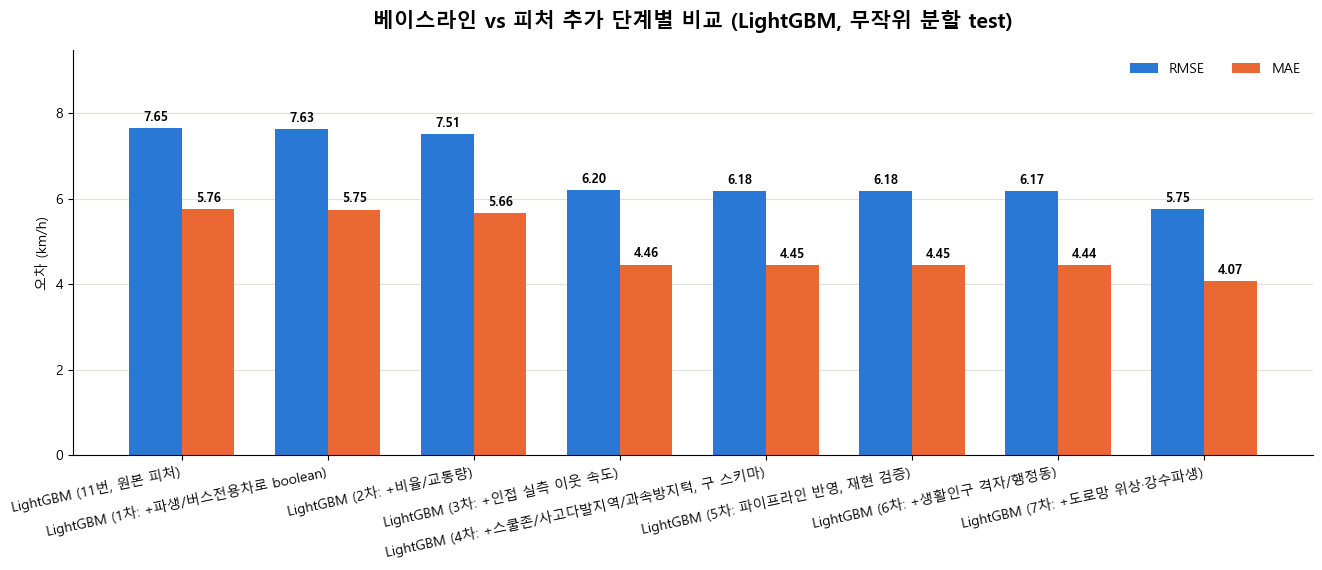

저장: C:\Users\ejjun\Desktop\seoul-eco-routing\docs\figures\model\04_derived_features_comparison_v5.png


In [10]:
labels = results_df["model"].tolist()
x = range(len(labels))
width = 0.36

fig, ax = plt.subplots(figsize=(13.5, 5.8))
ax.bar([i - width / 2 for i in x], results_df["rmse"], width, label="RMSE", color=COLOR_RMSE)
ax.bar([i + width / 2 for i in x], results_df["mae"], width, label="MAE", color=COLOR_MAE)
ax.set_xticks(list(x), labels, rotation=12, ha="right")
ax.set_title("베이스라인 vs 피처 추가 단계별 비교 (LightGBM, 무작위 분할 test)", fontsize=15, fontweight="bold", pad=16)
ax.set_ylabel("오차 (km/h)")
ax.legend(frameon=False, ncols=2, loc="upper right")

for patch in ax.patches:
    height = patch.get_height()
    ax.text(patch.get_x() + patch.get_width() / 2, height + 0.1, f"{height:.2f}",
            ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
top = ax.get_ylim()[1]
ax.set_ylim(0, top * 1.18)
fig.tight_layout()
fig.savefig(DOCS_FIGURES_DIR / "04_derived_features_comparison_v5.png", dpi=220, bbox_inches="tight")
plt.show()
print("저장:", DOCS_FIGURES_DIR / "04_derived_features_comparison_v5.png")

## 9. 피처 중요도 — 신규/파생 피처 순위

In [11]:
importance = pd.DataFrame({
    "feature": lgb_full.feature_name_,
    "gain": lgb_full.booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False)
importance["gain_share"] = importance["gain"] / importance["gain"].sum()
NEW_COLS_ALL = DERIVED_COLS + POPULATION_COLS + TOPO_COLS + RAIN_PEAK_NUMERIC_COLS + RAIN_PEAK_CATEGORICAL_COLS
importance["group"] = np.select(
    [importance["feature"] == "nearest_obs_neighbor_speed",
     importance["feature"].isin(TOPO_COLS),
     importance["feature"].isin(RAIN_PEAK_NUMERIC_COLS + RAIN_PEAK_CATEGORICAL_COLS),
     importance["feature"].isin(POPULATION_COLS),
     importance["feature"].isin(EXTERNAL_CONTEXT_COLS + SPARSE_NUMERIC_COLS)],
    ["이웃속도", "위상·파생(7차)", "강수·첨두파생(7차)", "생활인구(6차)", "외부컨텍스트"],
    default="도로기본/지형/시간",
)
importance["is_new"] = importance["feature"].isin(NEW_COLS_ALL)

print("=== 신규/파생 피처 순위(7차, 전체 피처 모델) ===")
print(importance[importance["is_new"]].head(25)[["feature", "group", "gain_share"]].to_string(index=False))
print()
print("=== 그룹별 gain 합계 ===")
print(importance.groupby("group")["gain_share"].sum().sort_values(ascending=False).round(4).to_string())
print()
print("=== 전체 상위 15개 ===")
print(importance.head(15)[["feature", "group", "gain_share"]].round(4).to_string(index=False))

=== 신규/파생 피처 순위(7차, 전체 피처 모델) ===
                     feature     group  gain_share
  nearest_obs_neighbor_speed      이웃속도    0.792280
             max_spd_x_lanes 위상·파생(7차)    0.026965
         traffic_volume_aadt    외부컨텍스트    0.012106
      downstream_speed_delta 위상·파생(7차)    0.007911
    length_x_node_complexity 위상·파생(7차)    0.007640
  t_node_incoming_lanes_mean 위상·파생(7차)    0.006608
    t_node_node_total_degree 위상·파생(7차)    0.006512
      f_node_node_out_degree 위상·파생(7차)    0.006273
    f_node_node_total_degree 위상·파생(7차)    0.004725
             node_complexity 위상·파생(7차)    0.004401
f_node_outgoing_max_spd_mean 위상·파생(7차)    0.003474
t_node_incoming_max_spd_mean 위상·파생(7차)    0.003455
  f_node_outgoing_lanes_mean 위상·파생(7차)    0.003289
                    grid_pop  생활인구(6차)    0.002914
  f_node_incoming_lanes_mean 위상·파생(7차)    0.002011
f_node_incoming_max_spd_mean 위상·파생(7차)    0.001741
  t_node_outgoing_lanes_mean 위상·파생(7차)    0.001675
t_node_outgoing_max_spd_mean 위상·파생(7차)    0.0015

## 요약

In [12]:
prev6 = results_df.iloc[6]   # 6차: +생활인구
curr7 = results_df.iloc[7]   # 7차: +위상·강수파생

print("=== 6차(+생활인구) 대비 7차(+위상·강수파생) 변화 ===")
print(f"RMSE: {prev6['rmse']:.3f} -> {curr7['rmse']:.3f} (Δ{prev6['rmse']-curr7['rmse']:+.3f})")
print(f"MAE:  {prev6['mae']:.3f} -> {curr7['mae']:.3f} (Δ{prev6['mae']-curr7['mae']:+.3f})")
print(f"R²:   {prev6['r2']:.3f} -> {curr7['r2']:.3f} (Δ{curr7['r2']-prev6['r2']:+.3f})")
print()
print("=== 구 4차(마이그레이션 전) 대비 5차 재현 오차 ===")
old_v4 = results_df.iloc[4]
prev5 = results_df.iloc[5]
print(f"RMSE: {old_v4['rmse']:.3f} -> {prev5['rmse']:.3f} (Δ{old_v4['rmse']-prev5['rmse']:+.3f})")
print(f"R²:   {old_v4['r2']:.3f} -> {prev5['r2']:.3f} (Δ{prev5['r2']-old_v4['r2']:+.3f})")
print()
print("=== 11번 베이스라인 대비 누적 변화 ===")
base = results_df.iloc[0]
print(f"RMSE: {base['rmse']:.3f} -> {curr7['rmse']:.3f} (Δ{base['rmse']-curr7['rmse']:+.3f})")
print(f"MAE:  {base['mae']:.3f} -> {curr7['mae']:.3f} (Δ{base['mae']-curr7['mae']:+.3f})")

=== 6차(+생활인구) 대비 7차(+위상·강수파생) 변화 ===
RMSE: 6.174 -> 5.754 (Δ+0.420)
MAE:  4.443 -> 4.068 (Δ+0.375)
R²:   0.746 -> 0.780 (Δ+0.033)

=== 구 4차(마이그레이션 전) 대비 5차 재현 오차 ===
RMSE: 6.180 -> 6.180 (Δ-0.000)
R²:   0.746 -> 0.746 (Δ+0.000)

=== 11번 베이스라인 대비 누적 변화 ===
RMSE: 7.653 -> 5.754 (Δ+1.899)
MAE:  5.765 -> 4.068 (Δ+1.697)


이 노트북은 파생/추가 피처가 도움이 되는지만 빠르게 확인하는 용도입니다(LightGBM 1개, 원본 하이퍼파라미터 그대로). 최종 파이프라인 반영 여부, 3개 모델 재비교, 하이퍼파라미터 튜닝은 여기서 개선 효과가 확인된 뒤 별도로 진행합니다.

캐시(`data/interim/notebook_cache/nb12_feature_cache_v6.parquet`)는 이 노트북 전용 임시 파일입니다 — `data/README.md`의 공식 파이프라인 산출물 목록에는 포함되지 않습니다.

**남은 가정/한계**: 추정교통량의 시간대 매칭(시간코드 1=0~1시)은 공식 문서로 확인된 게 아니라 순서 기반 가정입니다. 이 데이터는 2024년 평일 기준이라 2026년 7월(주말 포함) 관측과 시점·요일 구성이 다릅니다. 스쿨존 200m 버퍼는 실제 보호구역 경계(도로 형상 기준)가 아니라 직선거리 근사이고, `school_zone_count`는 `MAX_SPD`와 일부 중복 정보일 수 있습니다. 과속방지턱 원본 도형에 닫히지 않은 링 오류가 있어 `on_invalid="fix"`로 보정해서 읽었습니다 — 일부 폴리곤 형상이 원본과 미세하게 다를 수 있습니다.

**생활인구 관련 한계(4절)**: 격자/행정동 원본의 소량값 마스킹(`*`)을 0으로 처리했습니다(임시 처리, 정식으로 넣을 땐 재검토 필요). 링크→격자 매칭은 링크 중심점 1개로만 판정해 긴 링크의 실제 인구 노출과는 오차가 있을 수 있습니다. `grid_pop`/`dong_pop` 둘 다 대략 95% 매칭이라 나머지는 결측으로 남아 LightGBM 기본 결측 처리에 맡깁니다.

**7차(위상·강수파생) 관련 한계**: 도로망 위상·파생 28개는 `notebooks/13_tier_split_evaluation.ipynb`가 **공간 블록분할** 기준으로 검증한 값입니다(B +0.026~+0.031, C +0.043) — 이 노트북의 무작위 분할 결과는 그 효과를 과소평가하거나 다르게 보여줄 수 있습니다(9절 GroupKFold가 더 정직한 기준). 강수·첨두시 파생은 `src/11`과 달리 `시간코드 - 1`로 실제 시각을 보정해서 만들었습니다.

## 7. 공정한 재평가 — Section/Link GroupKFold (공간 일반화)

지금까지(11번, 1~7차)는 전부 **무작위 행 분할**이었습니다. 같은 링크의 다른 시간대 행이 train/test에 섞여 있어서, 사실상 "이미 아는 도로의 새 시간대"를 맞히는 문제였습니다 — `data/README.md`에 있는 Model B의 **"시간 일반화"(R²=0.740, T-data 기준)**와 성격이 비슷합니다.

Model B가 진짜 겨루는 문제는 "한 번도 안 본 도로"를 맞히는 **공간 일반화**(section GroupKFold, T-data 기준 **R²=0.641**)입니다. 5분 데이터는 T-data 때와 달리 관측 복제가 없어서 `source_section_id = LINK_ID`(`src/pipeline/05_build_speed_fact.py` 근거) — 즉 지금은 **LINK_ID 자체가 곧 section**입니다. `LINK_ID` 기준 GroupKFold를 쓰면 폴드마다 특정 링크들이 통째로 test로 빠져서, 그 링크의 어떤 시간대 행도 학습에 들어가지 않습니다.

**중요한 예외 처리**: `nearest_obs_neighbor_speed`는 우리 자신의 관측 데이터에서 파생된 피처라, 폴드마다 다시 계산해야 합니다 — "이 폴드에서 미관측이라고 치는 링크"의 실측값이 다른 링크의 이웃 피처로 새어 들어가면(=train에 있는 링크가 test 링크의 실측값을 이웃 피처로 참조) 평가가 부풀려집니다. 인접 그래프(`link_neighbors`)와 링크x시간 실측 행렬(`filled`/`valid`)은 3번 섹션에서 만든 걸 재사용하되, **그 폴드의 train 링크만 "이웃으로 인정"**하도록 희소행렬만 다시 만듭니다. 도로속성/위상/외부컨텍스트/생활인구/강수파생은 전부 외부 데이터이거나 우리 라벨과 무관한 정적 계산값(우리 라벨에서 파생되지 않음)이라 이 문제가 없어 그대로 재사용합니다.

3-fold로 진행합니다(팀 `experiments/eval_protocols.py`도 3-fold 기본값을 씁니다). 폴드마다 LightGBM을 새로 학습해야 해서 지금까지보다 시간이 더 걸립니다. 여기서부터는 **7차(전체 피처)** 기준으로만 평가합니다.

In [13]:
from sklearn.model_selection import GroupKFold

df["tm_key"] = df["기준일"].astype(str) + "_" + df["시간코드"].astype(int).astype(str)

N_FOLDS = 3
groups = df["LINK_ID"].values
gkf = GroupKFold(n_splits=N_FOLDS)

GROUP_FEATURE_COLS = FULL_FEATURE_COLS
GROUP_CATEGORICAL_COLS = FULL_CATEGORICAL_COLS


def build_neighbor_feature_for_allowed(allowed_links):
    """allowed_links(그 폴드의 train 링크)만 이웃으로 인정해 인접 실측 속도 재계산."""
    rows_i, cols_i = [], []
    for l in link_ids_sorted:
        i = link_idx[l]
        for n in link_neighbors.get(l, ()):
            if n in allowed_links:
                rows_i.append(i)
                cols_i.append(link_idx[n])
    A_fold = csr_matrix((np.ones(len(rows_i), dtype="float32"), (rows_i, cols_i)), shape=(n_links, n_links))
    num = A_fold @ filled
    den = A_fold @ valid
    with np.errstate(invalid="ignore", divide="ignore"):
        nm = num / den
    nm[den == 0] = np.nan
    return pd.DataFrame(nm, index=link_ids_sorted, columns=tm_columns) \
        .reset_index().rename(columns={"index": "LINK_ID"}) \
        .melt(id_vars="LINK_ID", var_name="tm_key", value_name="fold_neighbor_speed")


fold_rows = []
for fold_i, (train_idx, test_idx) in enumerate(gkf.split(df, groups=groups)):
    train_links = set(df["LINK_ID"].iloc[train_idx].unique())
    test_links = set(df["LINK_ID"].iloc[test_idx].unique())
    assert len(train_links & test_links) == 0, "링크가 train/test에 겹치면 안 됨"

    nm_long = build_neighbor_feature_for_allowed(train_links)
    fold_neighbor = df[["LINK_ID", "tm_key"]].merge(nm_long, on=["LINK_ID", "tm_key"], how="left")["fold_neighbor_speed"]

    Xf = df[GROUP_FEATURE_COLS].copy()
    Xf["nearest_obs_neighbor_speed"] = fold_neighbor.to_numpy(dtype="float32")
    yf = df[TARGET]

    X_train, X_test = Xf.iloc[train_idx], Xf.iloc[test_idx]
    y_train, y_test = yf.iloc[train_idx], yf.iloc[test_idx]

    model = lgb.LGBMRegressor(objective="regression", n_estimators=300, learning_rate=0.05,
                              num_leaves=63, random_state=RANDOM_STATE, verbosity=-1)
    model.fit(X_train, y_train, categorical_feature=GROUP_CATEGORICAL_COLS + ["dow"])
    pred = model.predict(X_test)

    row = evaluate(y_test, pred, f"fold{fold_i}")
    row["n_train_links"] = len(train_links)
    row["n_test_links"] = len(test_links)
    fold_rows.append(row)
    print(f"fold{fold_i}: train_links={len(train_links):,} test_links={len(test_links):,} "
          f"RMSE={row['rmse']:.3f} MAE={row['mae']:.3f} R2={row['r2']:.3f}")

    del nm_long, fold_neighbor, Xf, X_train, X_test, y_train, y_test, pred
    gc.collect()

group_results = pd.DataFrame(fold_rows)
group_results

fold0: train_links=29,973 test_links=14,987 RMSE=6.601 MAE=4.589 R2=0.708


fold1: train_links=29,974 test_links=14,986 RMSE=6.705 MAE=4.632 R2=0.701


fold2: train_links=29,973 test_links=14,987 RMSE=6.551 MAE=4.609 R2=0.715


,model,rmse,mae,r2,n_train_links,n_test_links
0,fold0,6.601023,4.589042,0.707770,29973,14987
1,fold1,6.705258,4.632354,0.701079,29974,14986
2,fold2,6.550823,4.608721,0.715391,29973,14987


In [14]:
GROUP_SUMMARY = {
    "model": "LightGBM (GroupKFold, 7차 전체 피처+위상+생활인구+강수파생)",
    "rmse": group_results["rmse"].mean(),
    "mae": group_results["mae"].mean(),
    "r2": group_results["r2"].mean(),
}
print("=== 3-fold 평균 (공간 일반화, 정직한 비교) ===")
print(f"RMSE={GROUP_SUMMARY['rmse']:.3f}  MAE={GROUP_SUMMARY['mae']:.3f}  R2={GROUP_SUMMARY['r2']:.3f}")
print()
print("=== 비교표 ===")
compare = pd.DataFrame([
    {"model": "Model B 공간일반화 (T-data, 팀 공식 벤치마크)", "rmse": 7.71, "mae": 5.61, "r2": 0.641},
    {"model": "Model B 공간일반화 (5분 데이터, src/11 재실행, 우리 피처 없음)", "rmse": 8.104321, "mae": 5.947932, "r2": 0.562342},
    {"model": "Model B 시간일반화 (T-data, 참고용)", "rmse": 6.43, "mae": 4.72, "r2": 0.740},
    results_df.iloc[7].to_dict(),  # 7차, 무작위 분할 (참고용 — 다른 평가방식)
    GROUP_SUMMARY,
])
print(compare[["model", "rmse", "mae", "r2"]].to_string(index=False))

=== 3-fold 평균 (공간 일반화, 정직한 비교) ===
RMSE=6.619  MAE=4.610  R2=0.708

=== 비교표 ===
                                       model     rmse      mae       r2
           Model B 공간일반화 (T-data, 팀 공식 벤치마크) 7.710000 5.610000 0.641000
Model B 공간일반화 (5분 데이터, src/11 재실행, 우리 피처 없음) 8.104321 5.947932 0.562342
                 Model B 시간일반화 (T-data, 참고용) 6.430000 4.720000 0.740000
                 LightGBM (7차: +도로망 위상·강수파생) 5.754122 4.068020 0.779592
LightGBM (GroupKFold, 7차 전체 피처+위상+생활인구+강수파생) 6.619035 4.610039 0.708080


**해석 기준**: `GROUP_SUMMARY`(공간 일반화, 5분 데이터 + 우리 피처 전체 + 위상 + 생활인구 + 강수파생)를 Model B 공간일반화 두 벤치마크(T-data 0.641, 5분 데이터+팀 피처만 0.562)와 비교하는 게 정직한 비교입니다. 무작위 분할 7차는 참고용일 뿐 이 비교의 대상이 아닙니다 — 평가 방식이 다른 숫자이기 때문입니다.

`models/11`의 팀 피처(노드 위상 등, `pipeline/04` 산출)와 이 노트북의 피처는 이제 도로망 위상까지 포함해 거의 같은 집합이 됐지만(생활인구만 이 노트북에만 있음), `models/11`은 아직 새 스키마로 옮겨지지 않았습니다(입력 경로가 삭제된 옛 병합 파일을 가리키는 상태) — 완전한 최종 비교는 `models/11`을 새 스키마로 옮긴 뒤 나옵니다.